Esse notebook tem como objetivo:
1. Caracterizar o laser utilizado para os experimentos no IDOR: $w_0$ (cintura do feixe), $z_R$ (comprimento de Rayleigh) e $z_0$ (distancia da cintura). Essa caracterização é feita para o feixe se propagando livremente, após a lente de bombeamento e do feixe contrapropagante (passando por todas as lentes).
2. Avaliar se as lentes utilizadas estão consistentes com as sugestões de otimização de acoplamento presentes no artigo "". Mais abaixo serão apresentadas as condições ótimas de acordo com as previsões teóricas do artigo (as simulações foram feitas em outro notebook).
3. Caso as lentes utilizadas não forem consistentes com os resultados do artigo, determinar possíveis combinações de lentes.

---



In [45]:
import numpy as np
import matplotlib.pyplot as plt
import math
import pandas as pd
from scipy.optimize import curve_fit

### Caracterização do feixe se propagando livremente

O feixe foi medido em 5 posições, coletando 7 dados por posição. A posição do perfilomêtro está apresentada na imagem abaixo e corresponde aos números 1,2,3,4 e 5.

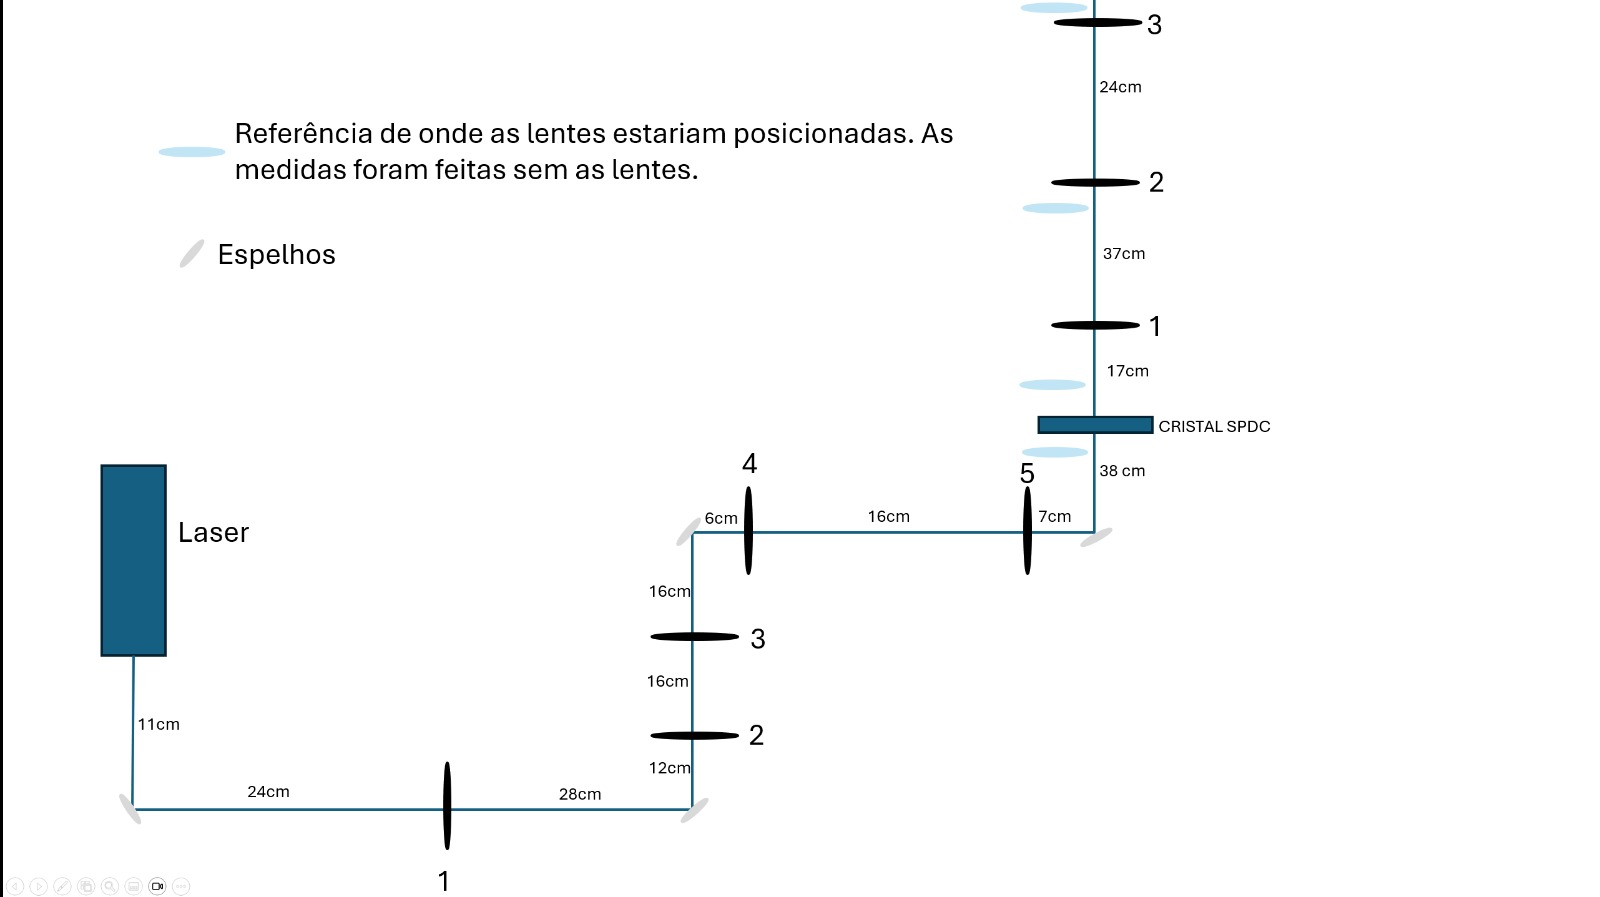


In [46]:
### Apartir da imagem acima:
z_livre = np.array([0, 40, 56, 78, 94])*1e-2 + (35e-2) # metros

In [47]:
livre1 = pd.read_csv("Livre/Data-1-seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
livre2 = pd.read_csv("Livre/Data-2-seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
livre3 = pd.read_csv("Livre/Data-3-seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
livre4 = pd.read_csv("Livre/Data-4-seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")
livre5 = pd.read_csv("Livre/Data-5-seq_#001.txt", sep="\t",skiprows=10,encoding="latin1")

In [48]:
### Exemplo dos dados:
livre1.head()

,Measurement,Time [hh:mm:ss:zzz],Peak Position X[µm],Peak Position Y[µm],Centroid Position X[µm],Centroid Position Y[µm],AD Saturation[%],Total Power[dBm],Beam Width Clip X[µm],Beam Width Clip Y[µm],Gaussian Intensity X[%],Gaussian Intensity Y[%],Gaussian Diameter X[µm],Gaussian Diameter Y[µm],Unnamed: 14
0,1,10:40:10.100,-208.61,-134.92,-183.44,-92.26,67.68,20.85,750.96,914.65,95.53,95.47,793.63,936.24,NaN
1,2,10:40:20.075,-180.28,-189.23,-184.35,-104.05,72.93,21.06,780.74,863.09,95.82,95.25,784.58,936.61,NaN
2,3,10:40:30.081,-149.59,-111.31,-176.06,-99.74,68.30,20.97,740.69,912.77,95.77,95.45,765.84,938.80,NaN
3,4,10:40:40.081,-227.50,-98.33,-184.74,-97.63,66.32,20.91,751.36,917.23,95.81,95.35,774.97,955.89,NaN
4,5,10:40:50.081,-182.12,-130.20,-170.01,-92.97,69.85,20.92,761.04,879.89,95.81,95.38,778.47,952.20,NaN


In [49]:
files = [livre1, livre2, livre3, livre4, livre5]

w_X, w_Y = [], []
std_wX, std_wY = [], []

for df in files:
    Dx = df["Gaussian Diameter X[µm]"] / 2
    Dy = df["Gaussian Diameter Y[µm]"] / 2

    w_X.append(Dx.mean())
    w_Y.append(Dy.mean())

    std_wX.append(Dx.std())
    std_wY.append(Dy.std())

# Convert to numpy arrays
w_X = np.array(w_X)
w_Y = np.array(w_Y)
std_wX = np.array(std_wX)
std_wY = np.array(std_wY)

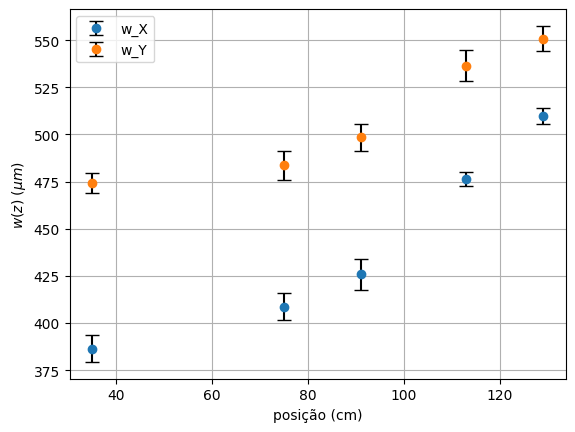

In [50]:
### Vamos plotar um exemplo:
plt.errorbar(z_livre*1e2, w_X, yerr = std_wX, fmt='o', ecolor='black', capsize=5, label = 'w_X')
plt.errorbar(z_livre*1e2, w_Y, yerr = std_wY, fmt='o', ecolor='black', capsize=5, label = 'w_Y')

plt.legend()
plt.grid()

plt.xlabel('posição (cm)')
plt.ylabel(r'$w(z)$ ($\mu m$)')

plt.show()

Agora vamos definir uma função que será usada nas outras caracterizações também. Essa função servirá para ajustar os nossos dados, com base na suposição que os feixes são gaussianos. A partir dessa suposição e do ajuste seremos capazes de encontrar os parâmetros desejados.

A teoria nos diz que a cintura do feixe se propaga no eixo $z$ descrito pela equação

$$
w(z) = w_0 \sqrt{1 + (\frac{z - z_0}{z_R})^2}
$$

Sendo assim faremos um ajuste de 3 parâmetros: $w_0$, $z_0$ e $z_R$. Poderemos também definir a divergência de nosso feixe:


$$
\theta = \frac{w_0}{z_R}
$$



Direção X:
  Raio da cintura w0 = 385.77 µm
  Posição da cintura z0 = 387.991 mm
  Comprimento de Rayleigh zR = 1037.343 mm
  Divergência = 0.372 mrad (0.0213°)

Direção Y:
  Raio da cintura w0 = 473.21 µm
  Posição da cintura z0 = 421.761 mm
  Comprimento de Rayleigh zR = 1427.071 mm
  Divergência = 0.332 mrad (0.0190°)


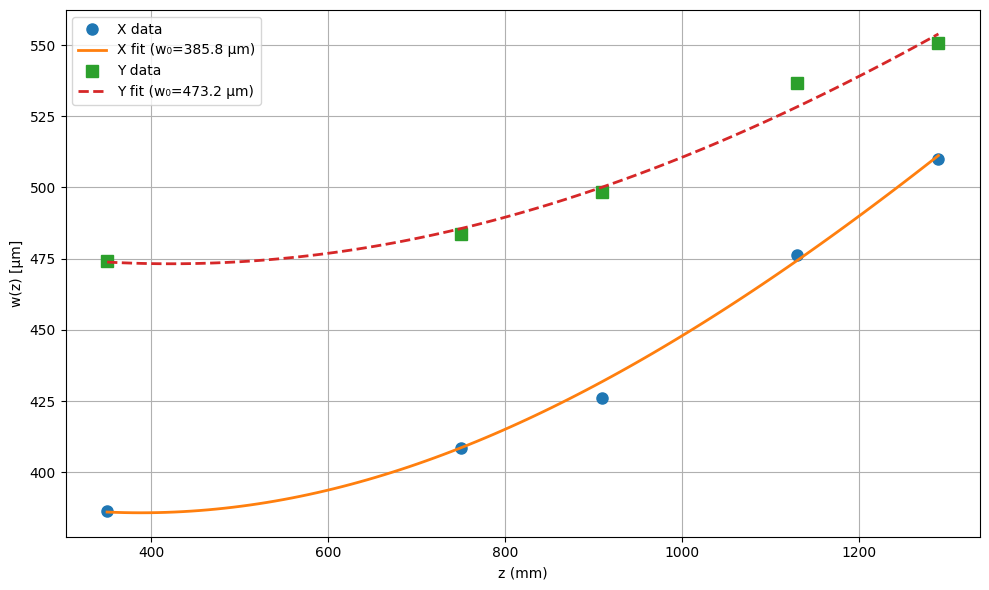

In [57]:
wx = np.array(w_X) * 1e-6
wy = np.array(w_Y) * 1e-6

sx = np.array(std_wX) * 1e-6
sy = np.array(std_wY) * 1e-6

# Gaussian beam equation
def gaussian_beam(z, w0, z0, zR):
    return w0 * np.sqrt(1 + ((z - z0) / zR)**2)

wavelength = 325e-9

# Initial guesses
p0_X = [wx.min(), -0.05, 2.0]
p0_Y = [wy.min(), -0.05, 2.0]

# Physical bounds
bounds = (
    [1e-9, -np.inf, 1e-6],
    [np.inf, np.inf, np.inf]
)

# Fit X
popt_X, pcov_X = curve_fit(
    gaussian_beam, z_livre, wx,
    p0=p0_X,
    bounds=bounds,
    sigma=sx,
    absolute_sigma=True,
    maxfev=20000
)

# Fit Y
popt_Y, pcov_Y = curve_fit(
    gaussian_beam, z_livre, wy,
    p0=p0_Y,
    bounds=bounds,
    sigma=sy,
    absolute_sigma=True,
    maxfev=20000
)

# Results
w0_X, z0_X, zR_X = popt_X
w0_Y, z0_Y, zR_Y = popt_Y



# Divergence (in radians)
divergence_X = w0_X/zR_X
divergence_Y = w0_Y/zR_Y

# Convert to milliradians and degrees
divergence_X_mrad = divergence_X * 1000
divergence_Y_mrad = divergence_Y * 1000

print("Direção X:")
print(f"  Raio da cintura w0 = {w0_X*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_X*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_X*1e3:.3f} mm")
print(f"  Divergência = {divergence_X_mrad:.3f} mrad ({np.degrees(divergence_X):.4f}°)")

print("\nDireção Y:")
print(f"  Raio da cintura w0 = {w0_Y*1e6:.2f} µm")
print(f"  Posição da cintura z0 = {z0_Y*1e3:.3f} mm")
print(f"  Comprimento de Rayleigh zR = {zR_Y*1e3:.3f} mm")
print(f"  Divergência = {divergence_Y_mrad:.3f} mrad ({np.degrees(divergence_Y):.4f}°)")

# Plot
z_fit = np.linspace(z_livre.min(), z_livre.max(), 100)
plt.figure(figsize=(10, 6))
plt.plot(z_livre*1e3, wx*1e6, 'o', label='X data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, *popt_X)*1e6, '-', label=f'X fit (w₀={w0_X*1e6:.1f} µm)', linewidth=2)
plt.plot(z_livre*1e3, wy*1e6, 's', label='Y data', markersize=8)
plt.plot(z_fit*1e3, gaussian_beam(z_fit, *popt_Y)*1e6, '--', label=f'Y fit (w₀={w0_Y*1e6:.1f} µm)', linewidth=2)
plt.xlabel('z (mm)')
plt.ylabel('w(z) [µm]')
plt.legend()
plt.grid()
plt.tight_layout()
plt.show()

### Parâmetros do feixe Gaussiano

| Parâmetro | Direção X | Direção Y |
|---|---:|---:|
| Raio da cintura ($w_0$) | 385.77 µm | 473.21 µm |
| Posição da cintura ($z_0$) | 38.8 cm | 42.2 cm |
| Comprimento de Rayleigh ($z_R$) | 1.04 m | 1.43 m |
| Divergência ($\theta$) | 0.372 mrad | 0.332 mrad |
| Divergência (°) | 0.0213° | 0.0190° |

Faltam ainda os dados para depois da lente de coleta e do feixe contra-propagante.

###